# How to: Estimate MTBF
Using pandaICTs reliability module to get the Mean Time Between Failure (MTBF) of a non-repairable ICT network.


## Introduction
When analyzing the reliability of different networks it is often useful to consider its **Mean Time Between Failure** (**MTBF**). In stochastical terms this corresponds to the expected value of the time until a system fails after starting in its fully functional state. In this tutorial we want to explore how we can use **pandaICTs Monte-Carlo based reliability module** to estimate the MTBF of an example network. In this example we will start with a network which is considered non-repairable, meaning once a component fails it never gets repaired. To do this let us start by declaring a simple ICT Network using pandaICT. Since this network will be non-repairable (MTTR = 0), MTBF and MTTF are identical. We'll see the difference in the next tutorial. For the purposes of this tutorial it is assumed that the user is familiar with the basic objects, concepts of pandaICT and knows how to declare basic ICT networks in pandaICT. First of all let us import everything:

In [1]:
import pandaict as pi
from pandaict import inspect
from demo_networks import simple_net, triangle_net
from pandaict.utils.enums import *
from pandaict.reliability.reliability import estimate_mtbf_mttr_for_conn, plot_graph

## Example 1: simple_net
As always we will start by declaring an ICT Network. Since the network declaration part is not supposed to be the center of this demonstration we'll import the **simple_net** Network we explored in earlier tutorials:

In [2]:
# =============================================
# simple_net
#
# {appA}~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~{appB}
#   |                                   |
# [Alice] --- (nodeA) --- (nodeB) --- [Bob]
#                      |
#               mtbf_h = 8760h
# =============================================

net, appA, appB = simple_net()

As always lets check if everything is set up correctly:

In [3]:
inspect(net, verbose=True)

----------- INSPECTION PASSED -----------


True

To refresh our memories lets plot the **simple_net** network using the build in `plot_graph` function, which plots a simplified graph-version of our network:

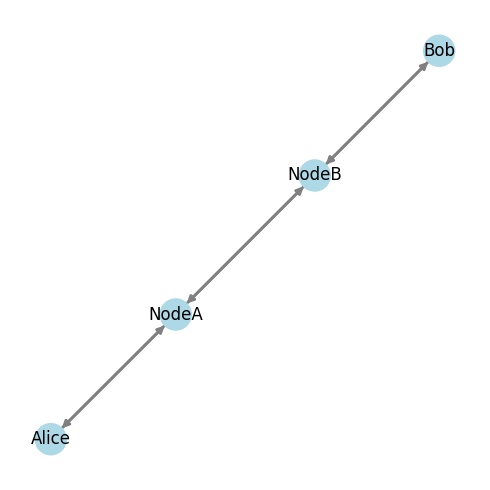

In [4]:
plot_graph(net)

Seeing that everything is declared properly next lets declare the connection. The connection is an essential part of the reliability calculation since it defines which endpoints are required to be able to communicate for us to consider the network as functional.

In [5]:
connection = pi.create_ict_connection(net, name='Alice->Bob', from_app=appA, to_app=appB, protocol='TCP')

In this example we will use only one connection for the reliability calculation. Further into this series we will also explore the more advanced capabilities of pandaICT to take into account multiple connection elements and such more complex functionality requirements for the network. To get the **MTBF** we will call the `estimate_mtbf_mttr_for_conn` function.

In [6]:
result = estimate_mtbf_mttr_for_conn(net, [connection])

Running 100000 simulations in parallel...


By default 100000 Monte-Carlo samples are collected. Lets take a look at the estimated MTBF by unpacking the results dictionary:

In [7]:
print('Mean Time Between Failure (MTBF) =', round(result['mtbf_h'],2), 'h')

Mean Time Between Failure (MTBF) = 8812.88 h


Since the System is non-repairable the MTBF is identical to the MTTF and the MTTR is infinite:

In [8]:
print('Mean Time Between Failure (MTBF) =', round(result.get('mtbf_h'),2), 'h')
print('Mean Time To Failure (MTTF)      =', round(result.get('mttf_h'),2), 'h')
print('Mean Time To Repair (MTTR)       =', round(result.get('mttr_h'),2))

Mean Time Between Failure (MTBF) = 8812.88 h
Mean Time To Failure (MTTF)      = 8812.88 h
Mean Time To Repair (MTTR)       = inf


Since in this case we know to expect 8760 h as the MTBF, let us calculate the relative error

In [9]:
MTBF = result['mtbf_h']
error = round(abs(8760-MTBF)/8760, 4)
print('relative Error =', error, '=', error*100, '%')

relative Error = 0.006 = 0.6 %


Here we should see that the error is already below 1 %. If one should be interested in a more precise result, we can simply increase the number of samples being collected by setting N to the desired number of samples inside `estimate_mtbf_mttr_for_conn`. This naturally scales with linear complexity O(n). In this case lets choose $10^7$ samples and calculate the error again.

In [10]:
result = estimate_mtbf_mttr_for_conn(net, [connection], N=int(1e7))
print('Mean Time Between Failure (MTBF) =', round(result['mtbf_h'],2), 'h')
MTBF = result['mtbf_h']
error = round(abs(8760-MTBF)/8760, 4)
print('relative Error =', error, '=', round(error*100, 4), '%')

Running 10000000 simulations in parallel...
Mean Time Between Failure (MTBF) = 8762.03 h
relative Error = 0.0002 = 0.02 %


In this case the error should be far below 0.1 % which shows that the method for this case converges toward the true solution. One could keep increasing the number of samples collected to get better and better results. Though right now we advice the users not to exceed $10^9$ samples since those are stored as `float64` datatypes and a quick calculation shows that this occupies around 8 Gb (!) of your RAM.

## Example 2: Triangle
Next let us take a look at a little more complex example: We will again create a simple network with two devices (Alice, Bob) talking to each other. To make things more interesting we will give those two devices two routes to send messages across which will containing a total of three nodes (A, B, C) which are subject to failure. We'll give those nodes a mean lifetime of one year (8760 h) and for the sake of simplicity set a custom std_type for the links such that they are perfect and never fail.

In [11]:
net, appA, appB = triangle_net(mtbf_h=8760,mttr_h=0)

Now that we have declared our ICT network lets inspect:

In [12]:
inspect(net, verbose=True)

----------- INSPECTION PASSED -----------


True

Again lets take a look at the corresponding graph by plotting it:

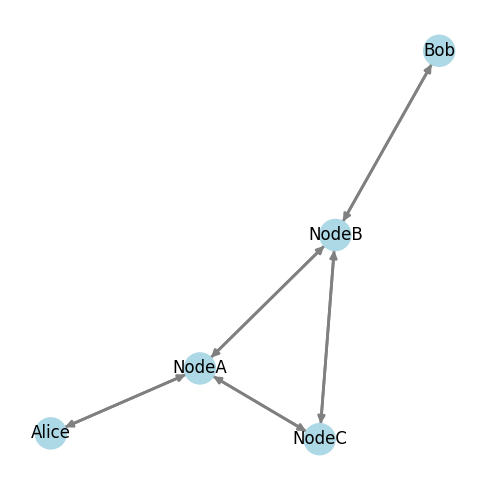

In [13]:
plot_graph(net)

Seeing that everything is declared properly next lets declare the connection. The connection is an essential part of the reliability calculation since it defines which endpoints are required to be able to communicate for us to consider the network as functional.

In [14]:
connection = pi.create_ict_connection(net, name='Alice->Bob', from_app=appA, to_app=appB, protocol='TCP')

Now with this connection we can start calculating the Mean Time Between Failure (MTBF) meaning the expected time for the network to keep functioning until failure, which in this case means Alice can talk to Bob and vice versa. For this we call the function ```estimate_mtbf_mttr_for_conn```:

In [15]:
result = estimate_mtbf_mttr_for_conn(net, [connection])

Running 100000 simulations in parallel...


By default 100000 Monte-Carlo samples are collected. Lets take a look at the results:

In [16]:
print('Mean Time Between Failure (MTBF) =', round(result['mtbf_h'],2), 'h')

Mean Time Between Failure (MTBF) = 4380.73 h


We should see something like 4360 h which is already an important result since it shows that this network is more reliable than either route would be on its own. One might say that this is obvious since we introduced some redundance in the topology. But a tool like this also allows us to explore much more complicated topologies for which it might not be that obvious.

Next: **How to MTBF & MTTR Estimation** — what changes when components can be repaired.